# Модель платформи цифрового двійника НСПТ

**Мова моделі:** SysML v2 (SysML v2 Pilot Implementation, ядро Jupyter).

## Крок 9. Модель вимог

Усі функціональні (FR) і нефункціональні (NFR) вимоги з `docs/requirements.md` з тими самими ідентифікаторами, згруповані за доменами ISO 23247:

| Пакет | Домен ISO 23247 | Вимоги |
|---|---|---|
| `DCE_DeviceCommunication` | зв'язок із пристроями | FR-01, FR-08, NFR-04 |
| `DTE_DigitalTwin` | цифровий двійник | FR-03, FR-04, FR-06, FR-07, NFR-01, NFR-03 |
| `UE_User` | користувач | FR-05, NFR-02, NFR-06 |
| `CrossCutting` | наскрізна сутність | FR-02, NFR-05 |

Запуск: **Kernel → Restart Kernel and Run All Cells**.

In [1]:
package PumpStationTwin_Requirements {
    doc /* Вимоги до платформи цифрового двійника НСПТ, згруповані за доменами ISO 23247. */

    package DCE_DeviceCommunication {
        doc /* Домен зв'язку з пристроями: збирання даних і керування пристроями. */

        requirement <'FR-01'> telemetryCollection {
            doc /* Платформа приймає всі сигнали реєстру (S-01 – S-16) через MQTT із частотами з реєстру;
                 * кожне повідомлення містить ідентифікатор сигналу, мітку часу й значення;
                 * у разі втрати зв'язку шлюз буферизує телеметрію щонайменше 1 год. */
        }
        requirement <'FR-08'> remoteControl {
            doc /* Оператор змінює уставку тиску (4,0–6,0 бар), пускає й зупиняє Н1 і Н2, перемикає режим;
                 * команда виконана лише коли reported = desired, без підтвердження за 10 с — тривога;
                 * у сервісному режимі команди відхиляються. */
        }
        requirement <'NFR-04'> commandLatency {
            doc /* Від надсилання команди до підтвердження станцією ≤ 3 с для 95 % команд. */
        }
    }

    package DTE_DigitalTwin {
        doc /* Домен цифрового двійника: застосунки й служби, доступ до ресурсів, функціонування й керування. */

        requirement <'FR-03'> stateSync {
            doc /* Платформа зберігає reported і desired стан насосів і станції;
                 * понад 5 с без даних — стан позначається як застарілий. */
        }
        requirement <'FR-04'> historyStorage {
            doc /* Історія сигналів за рівнями гарячий / теплий / холодний; журнал подій, тривог і команд. */
        }
        requirement <'FR-06'> alarms {
            doc /* Тривоги за порогами (тиск на виході < 3 бар, вібрація > 4,5 мм/с) і за подіями
                 * (сухий хід, аварія насоса) з квитуванням оператором. */
        }
        requirement <'FR-07'> analytics {
            doc /* Енергоефективність кожного насоса (кВт·год на 1 м³) і виявлення аномалій вібрації
                 * та температури; результати — лише рекомендації. */
        }
        requirement <'NFR-01'> syncLatency {
            doc /* Від мітки часу на шлюзі до оновлення стану двійника в API ≤ 500 мс для 95 % оновлень. */
        }
        requirement <'NFR-03'> scalability {
            doc /* Перехід з 1 до 10 станцій збільшує 95-й перцентиль затримки синхронізації
                 * не більш ніж на 30 % і без втрати повідомлень. */
        }
    }

    package UE_User {
        doc /* Домен користувача: подання стану оператору та інженеру. */

        requirement <'FR-05'> visualization {
            doc /* Дашборд поточних значень, тренди будь-якого сигналу, 3D-сцена станції
                 * з кольором стану насоса. */
        }
        requirement <'NFR-02'> endToEndLatency {
            doc /* Значення на екрані ≤ 1 с після зчитування на шлюзі для 95 % оновлень;
                 * аварійна тривога на екрані ≤ 2 с після події — для кожної події. */
        }
        requirement <'NFR-06'> sceneSmoothness {
            doc /* ≥ 99 % кадрів 3D-сцени формуються за ≤ 33,3 мс; оновлення стану не блокують рендеринг. */
        }
    }

    package CrossCutting {
        doc /* Наскрізна сутність: захищеність, якість даних, взаємодійність. */

        requirement <'FR-02'> dataQuality {
            doc /* Платформа відкидає дублікати й значення поза діапазоном реєстру
                 * і фіксує їх у журналі якості даних. */
        }
        requirement <'NFR-05'> security {
            doc /* MQTT і API — лише через TLS з автентифікацією; команди — лише роль «оператор»;
                 * 100 % команд у журналі. */
        }
    }
}


Package PumpStationTwin_Requirements (89f17eee-4a55-4236-adf9-f6e2a472a58c)


### Діаграми вимог за доменами ISO 23247

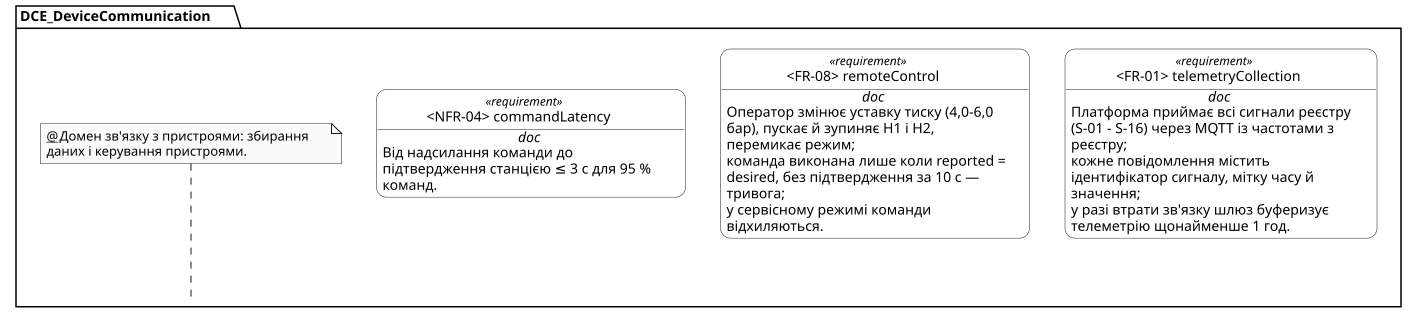

In [2]:
%viz --view=tree PumpStationTwin_Requirements::DCE_DeviceCommunication

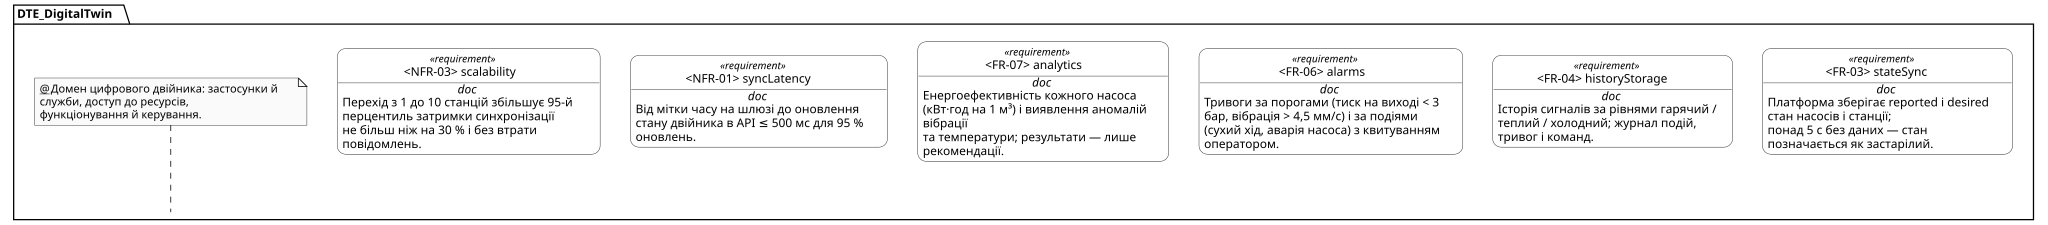

In [3]:
%viz --view=tree PumpStationTwin_Requirements::DTE_DigitalTwin

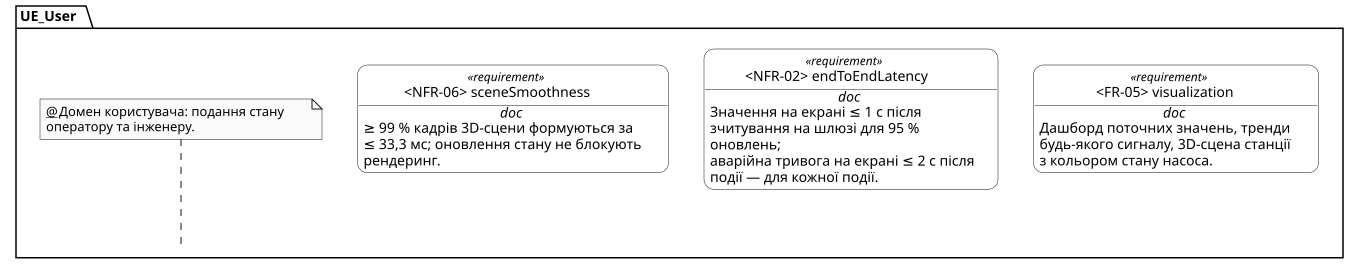

In [4]:
%viz --view=tree PumpStationTwin_Requirements::UE_User

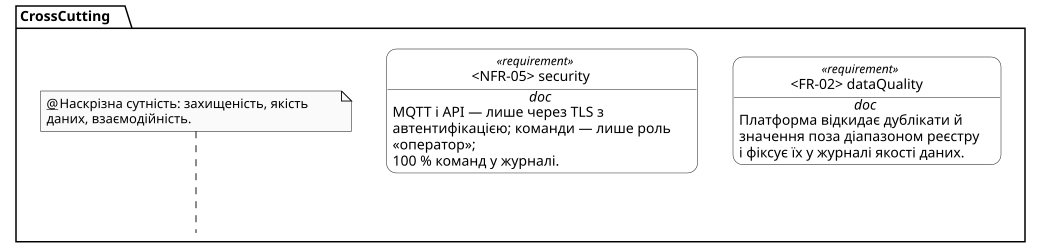

In [5]:
%viz --view=tree PumpStationTwin_Requirements::CrossCutting